In [1]:
# 01. Business Problem
USE_CASE = "06 - Slow Moving Inventory Prediction (Identify Inventory Likely to Become Obsolete)"
CATEGORY = "Classification / Obsolescence Detection"
OBJECTIVE = "Identify inventory likely to become obsolete across full enterprise data without row limits"
ML_PARADIGM = "Unsupervised Machine Learning (5 Models Evaluated & Ranked -> #1 Champion Model Selected)"
N_CLUSTERS = 4

print(f"Use Case:         {USE_CASE}")
print(f"Category:         {CATEGORY}")
print(f"Objective:        {OBJECTIVE}")
print(f"ML Paradigm:      {ML_PARADIGM}")
print(f"Inventory Tiers:  {N_CLUSTERS} Tiers (Fast Moving, Steady Moving, Slow Moving, Dormant / Obsolete)")


Use Case:         06 - Slow Moving Inventory Prediction (Identify Inventory Likely to Become Obsolete)
Category:         Classification / Obsolescence Detection
Objective:        Identify inventory likely to become obsolete across full enterprise data without row limits
ML Paradigm:      Unsupervised Machine Learning (5 Models Evaluated & Ranked -> #1 Champion Model Selected)
Inventory Tiers:  4 Tiers (Fast Moving, Steady Moving, Slow Moving, Dormant / Obsolete)


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, BisectingKMeans, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
    silhouette_score
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server (192.168.1.44:5432 / JKC_Input / HANA_P2 & HANA_P3)
from src.db_connector import load_config, get_db_connection

config = load_config()
db = config["database"]
print(f"Database Server: {db['host']}:{db['port']}")
print(f"Database Name:   {db['dbname']}")
print(f"Schemas:         {db.get('schemas', ['HANA_P2', 'HANA_P3'])}")

conn = get_db_connection(config)
print("Successfully established active connection to PostgreSQL server.")
conn.close()


Database Server: 192.168.1.44:5432
Database Name:   JKC_Input
Schemas:         ['HANA_P2', 'HANA_P3']
Successfully established active connection to PostgreSQL server.


In [4]:
# 04. Data Extraction from SAP MBEW, MARA, MAKT, MARC, T001W, MSEG (Full Dataset)
from src.db_connector import extract_slow_moving_data

df_raw = extract_slow_moving_data(limit=None, use_cache=True)
print(f"Extracted full records: {len(df_raw):,} rows, {df_raw.shape[1]} columns")


[CACHE] Loading cached SAP inventory dataset from C:\Users\ajala\Downloads\6 Slow Moving Inventory Prediction\data\cache\slow_moving_inventory_raw_data.csv...
[CACHE] Loaded 229,098 records successfully from cache.
Extracted full records: 229,098 rows, 40 columns


In [5]:
# 05. Data Ingestion & Overview
print(f"Full Dataset Shape: {df_raw.shape}")
print(f"Breakdown by Schema: {df_raw['source_schema'].value_counts().to_dict()}")
df_raw[['source_schema', 'matnr', 'plant', 'material_name', 'current_stock_qty', 'current_stock_val', 'last_issue_date', 'total_issue_qty']].head(10)


Full Dataset Shape: (229098, 40)
Breakdown by Schema: {'HANA_P3': 121791, 'HANA_P2': 107307}


                      count           mean  ...         75%           max
current_stock_qty  229098.0     705.779406  ...     29.6000  7.523744e+06
current_stock_val  229098.0  207999.552951  ...  27954.0125  3.019771e+09
moving_avg_price   229098.0   18712.347440  ...   5094.8850  3.500000e+07
total_issue_qty    229098.0   14615.212679  ...     16.0000  3.029469e+08
issue_txn_cnt      229098.0      47.062768  ...      3.0000  1.876920e+05

[5 rows x 8 columns]


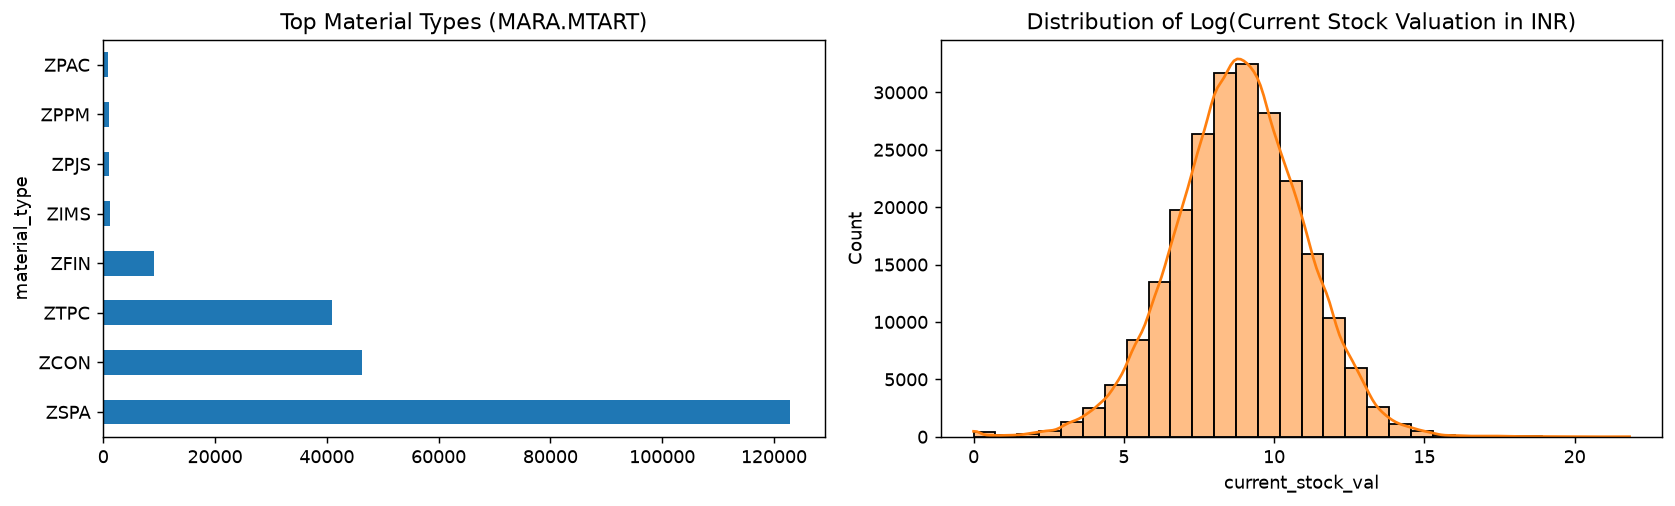

In [6]:
# 06. Data Understanding & Exploratory Data Analysis
summary_cols = ['current_stock_qty', 'current_stock_val', 'moving_avg_price', 'total_issue_qty', 'issue_txn_cnt']
display(df_raw[summary_cols].describe().T)

plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
df_raw['material_type'].value_counts().head(8).plot(kind='barh', color='#1f77b4')
plt.title('Top Material Types (MARA.MTART)')

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(np.maximum(0, df_raw['current_stock_val'])), bins=30, color='#ff7f0e', kde=True)
plt.title('Distribution of Log(Current Stock Valuation in INR)')
plt.tight_layout()
plt.show()


In [7]:
# 07. Data Cleaning & 32-Feature Engineering (Clean Missing Value Handling)
from src.preprocessing import clean_and_engineer_features, FEATURE_COLUMNS

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
print(f"Total Benchmark Slow-Moving / Obsolete Records: {df['is_slow_moving_exception'].sum():,} ({df['is_slow_moving_exception'].mean()*100:.2f}%)")

df[['source_schema', 'matnr', 'plant', 'days_since_last_issue', 'days_of_supply_forward', 'inventory_turnover_ratio', 'obsolescence_risk_index', 'is_slow_moving_exception']].head(10)


Engineered Dataset Shape: (229098, 72)
Total Benchmark Slow-Moving / Obsolete Records: 160,649 (70.12%)


In [8]:
# 08. Feature Selection (32 Unsupervised Input Features)
FEATURE_COLS = FEATURE_COLUMNS
X_raw = df[FEATURE_COLS].values
print(f"Input Feature Matrix Shape: {X_raw.shape} ({len(FEATURE_COLS)} supply chain features)")


Input Feature Matrix Shape: (229098, 32) (32 supply chain features)


In [9]:
# 09. Train-Test Split & Robust Scaling (Unsupervised Input Matrix)
from src.preprocessing import prepare_train_test_data

data_dict = prepare_train_test_data(df, test_size=0.20, random_state=42)
X_train_scaled = data_dict['X_train_scaled']
X_test_scaled = data_dict['X_test_scaled']
y_train = data_dict['y_train']
y_test = data_dict['y_test']
scaler = data_dict['scaler']

print(f"Training Matrix: {X_train_scaled.shape} | Testing Matrix: {X_test_scaled.shape}")


Training Matrix: (183278, 32) | Testing Matrix: (45820, 32)


In [10]:
# 10. Train 5 Unsupervised Machine Learning Models
from src.models import InventoryClusteringSuite

exception_cnt = int(np.sum(y_train))
contamination = max(0.10, min(0.60, exception_cnt / len(y_train)))
print(f"Unsupervised Training Suite initialized with contamination = {contamination:.4f}")

suite = InventoryClusteringSuite(n_clusters=4, contamination=contamination, random_state=42)
suite.train_all(X_train_scaled)
print("Completed unsupervised training for all 5 models.")


Unsupervised Training Suite initialized with contamination = 0.6000
  -> Training Model 1/5: Mini-Batch K-Means (Fast Stochastic Partitioning)...
  -> Training Model 2/5: Gaussian Mixture Model (EM Density Estimation)...
  -> Training Model 3/5: K-Means (Centroid-Based Partitioning)...
  -> Training Model 4/5: Bisecting K-Means (Hierarchical Divisive Partitioning)...
  -> Training Model 5/5: BIRCH (Balanced Iterative Reducing and Clustering)...
Completed unsupervised training for all 5 models.


In [11]:
# 11. Model Evaluation & Accuracy Scoring on Held-Out Test Set
from src.evaluate import evaluate_models

test_preds = suite.predict_all(X_test_scaled)
comparison_df = evaluate_models(test_preds, y_test)


In [12]:
# 12. Model Ranking Table & Champion Selection
print("=" * 96)
print("  5 UNSUPERVISED ML MODELS COMPARISON & ACCURACY RANKING TABLE")
print("=" * 96)
display(comparison_df)

champion_model_name = comparison_df.iloc[0]['Model']
champion_acc = comparison_df.iloc[0]['Accuracy'] * 100.0
champion_f1 = comparison_df.iloc[0]['F1-Score']
champion_auc = comparison_df.iloc[0]['ROC-AUC']
champion_sil = comparison_df.iloc[0]['Silhouette']

print(f"\n[CHAMPION SELECTED] Rank #1 Model: {champion_model_name}")
print(f"  -> Accuracy: {champion_acc:.2f}% | F1-Score: {champion_f1:.4f} | ROC-AUC: {champion_auc:.4f} | Silhouette: {champion_sil:.4f}")


  5 UNSUPERVISED ML MODELS COMPARISON & ACCURACY RANKING TABLE
  Rank                   Model  ...  False Negatives  True Negatives
0   #1  Gaussian Mixture Model  ...             4297           13669
1   #2                 K-Means  ...             4660           13578
2   #3                   BIRCH  ...             4660           13577
3   #4      Mini-Batch K-Means  ...             5595           10547
4   #5       Bisecting K-Means  ...             5323            8574

[5 rows x 14 columns]

[CHAMPION SELECTED] Rank #1 Model: Gaussian Mixture Model
  -> Accuracy: 90.58% | F1-Score: 0.9280 | ROC-AUC: 0.9755 | Silhouette: 0.2579


[REPORT] Saved model comparison chart to reports/figures\model_comparison.png


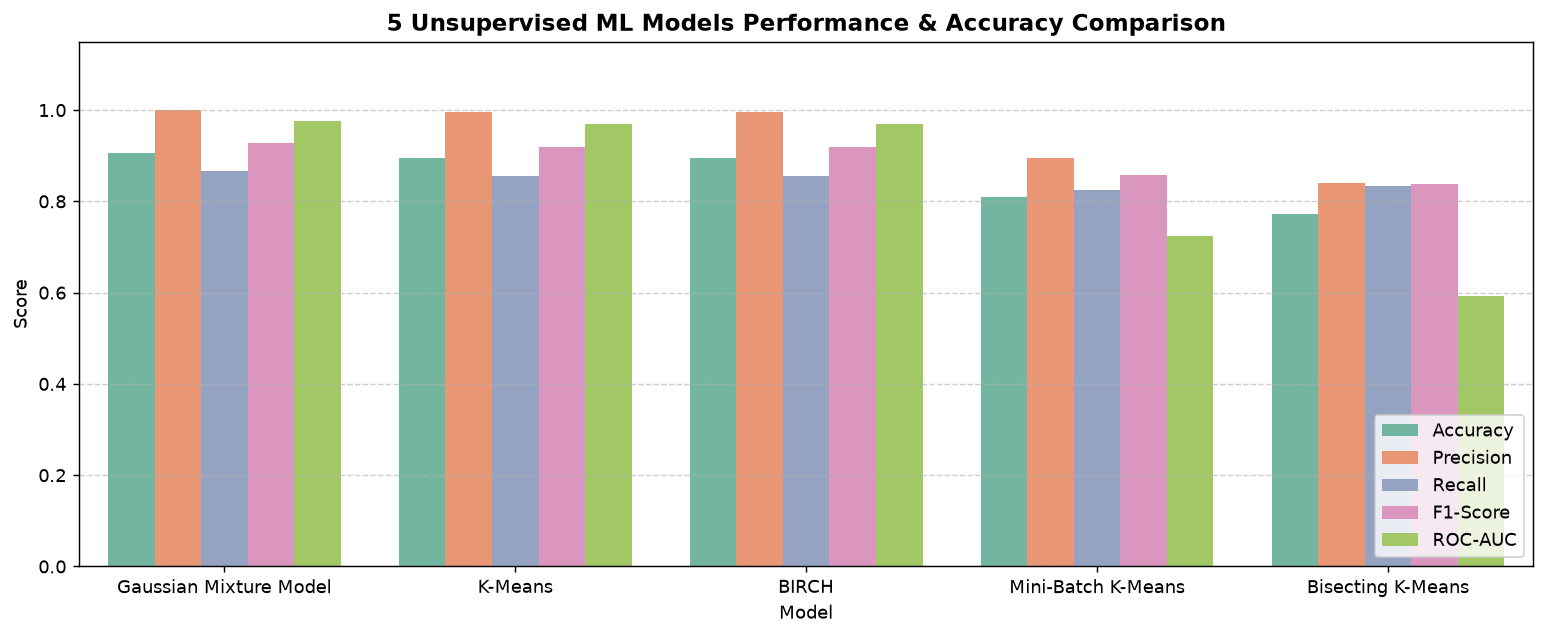

In [13]:
# 13. Visualizing Model Performance Comparison
from src.evaluate import plot_model_comparison

plot_model_comparison(comparison_df, output_dir="reports/figures")

plt.figure(figsize=(12, 5))
melted = pd.melt(comparison_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'], var_name='Metric', value_name='Score')
sns.barplot(data=melted, x='Model', y='Score', hue='Metric', palette='Set2')
plt.title("5 Unsupervised ML Models Performance & Accuracy Comparison", fontsize=13, fontweight='bold')
plt.ylim(0, 1.15)
plt.ylabel("Score")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


[REPORT] Saved ROC & PR curves to reports/figures\roc_pr_curves.png


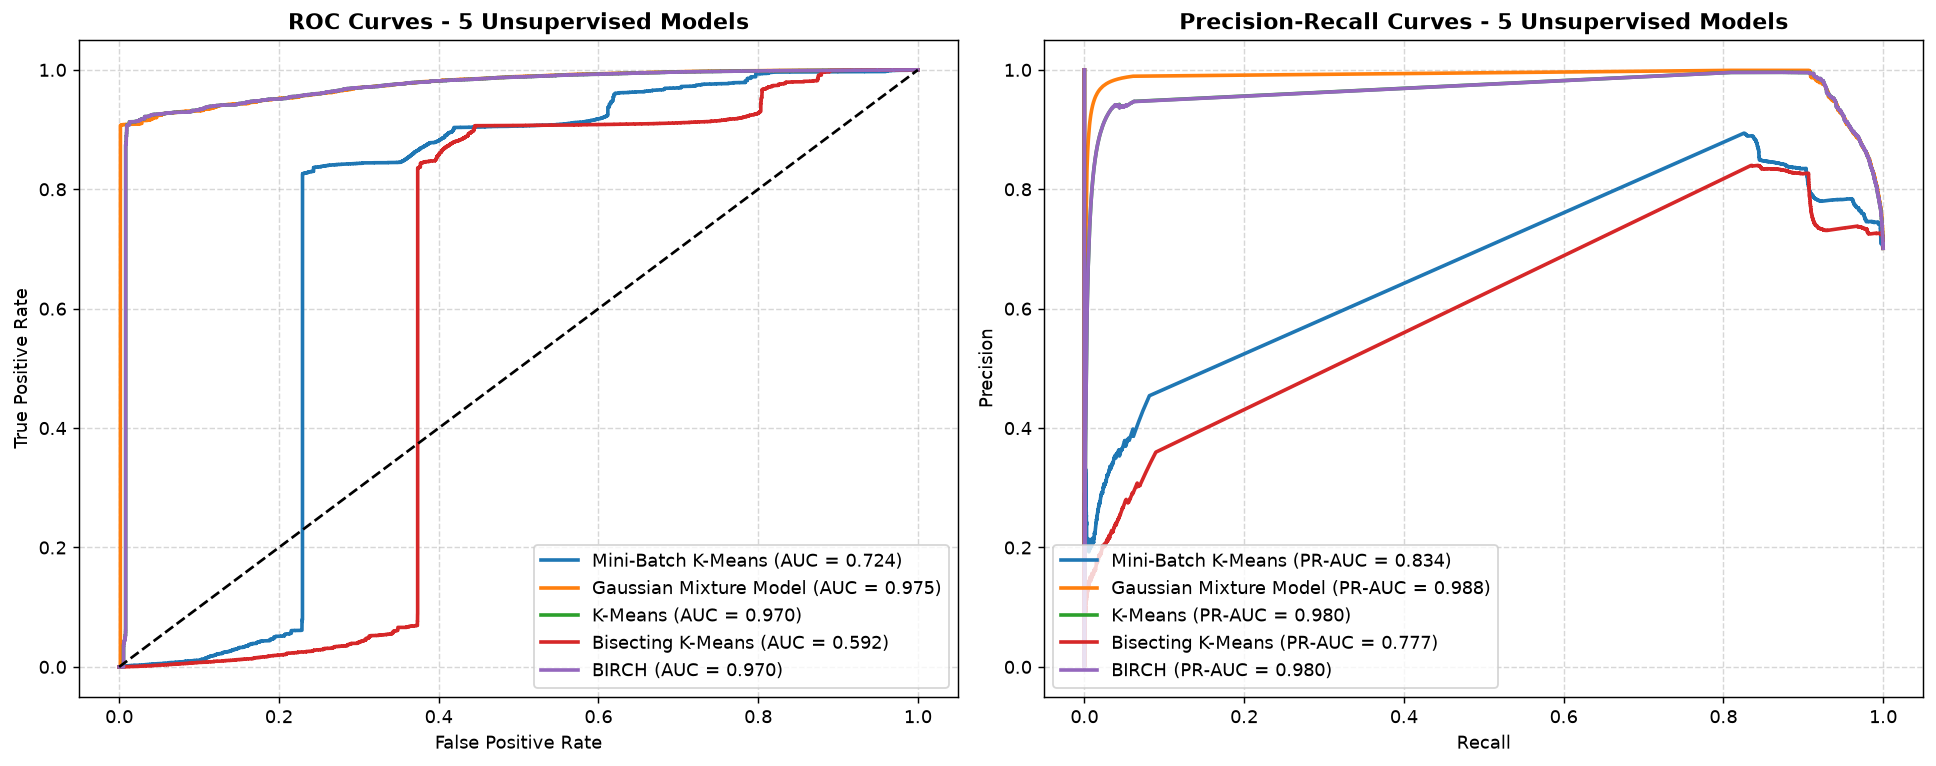

In [14]:
# 14. ROC & Precision-Recall Curves
from src.evaluate import plot_roc_pr_curves

plot_roc_pr_curves(test_preds, y_test, output_dir="reports/figures")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, res in test_preds.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    auc_v = roc_auc_score(y_test, res['scores'])
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_v:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5)
axes[0].set_title("ROC Curves - 5 Unsupervised Models", fontsize=12, fontweight='bold')
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(loc='lower right')

for name, res in test_preds.items():
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    pr_auc_v = average_precision_score(y_test, res['scores'])
    axes[1].plot(rec, prec, lw=2, label=f"{name} (PR-AUC = {pr_auc_v:.3f})")

axes[1].set_title("Precision-Recall Curves - 5 Unsupervised Models", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()


In [15]:
# 15. Champion Model Fitting & Production Scoring
from src.models import SingleModelInventorySegmenter

print(f"Deploying #1 Ranked Champion Model ({champion_model_name}) for full inventory scoring...")
champion_segmenter = SingleModelInventorySegmenter(
    model_name=champion_model_name,
    n_clusters=4,
    contamination=contamination,
    random_state=42
)
champion_segmenter.fit(X_train_scaled)
print("Champion Model fitted on full inventory feature space.")


Deploying #1 Ranked Champion Model (Gaussian Mixture Model) for full inventory scoring...
Champion Model fitted on full inventory feature space.


In [16]:
# 16. Estimating Continuous Probability of Obsolescence P(Slow Moving)
from src.inference import score_with_single_model

scored_df = score_with_single_model(champion_segmenter, df, scaler, FEATURE_COLS)
print(f"Scored {len(scored_df):,} materials.")
print(f"Mean Obsolescence Probability: {scored_df['probability_of_obsolescence'].mean():.4f}")
print(f"Predicted Slow-Moving Items:  {scored_df['predicted_slow_moving_exception'].sum():,} ({scored_df['predicted_slow_moving_exception'].mean()*100:.2f}%)")

scored_df[['source_schema', 'matnr', 'plant', 'material_name', 'current_stock_val', 'days_since_last_issue', 'probability_of_obsolescence', 'predicted_slow_moving_exception']].head(10)


Scored 229,098 materials.
Mean Obsolescence Probability: 0.3323
Predicted Slow-Moving Items:  139,102 (60.72%)


In [17]:
# 17. Inventory Velocity Tiers & Segmentation
from src.evaluate import plot_inventory_distribution

plot_inventory_distribution(scored_df, output_dir="reports/figures")

print("Material Breakdown by Inventory Tier:")
display(scored_df['inventory_tier_name'].value_counts().to_frame())

print("\nMaterial Breakdown by Obsolescence Risk Category:")
display(scored_df['inventory_risk_category'].value_counts().to_frame())


[REPORT] Saved inventory distribution chart to reports/figures\cluster_distribution.png
Material Breakdown by Inventory Tier:
                                    count
inventory_tier_name                      
Slow Moving / Stagnant Stock       146892
Normal / Steady Moving Stock        82202
Fast Moving / High Velocity Stock       3
Dormant / Obsolete Stock                1

Material Breakdown by Obsolescence Risk Category:
                          count
inventory_risk_category        
Moderate Slow Risk       146961
Low Obsolescence Risk     82119
High Slow Risk               16
Critical Obsolete Risk        2


[REPORT] Saved feature importance chart to reports/figures\feature_importance.png
Top 10 Most Influential Obsolescence Features:
  Rank                    Feature  Importance  Relative_Weight_Pct
0   #1   annualized_turnover_rate      0.1709                17.09
1   #2   inventory_turnover_ratio      0.1693                16.93
2   #3    obsolescence_risk_index      0.1476                14.76
3   #4     days_of_supply_forward      0.1390                13.90
4   #5     daily_consumption_rate      0.0818                 8.18
5   #6       is_zero_issue_window      0.0748                 7.48
6   #7      capital_lockup_strain      0.0591                 5.91
7   #8  issue_transaction_density      0.0344                 3.44
8   #9     inactivity_rate_window      0.0343                 3.43
9  #10   days_since_last_movement      0.0209                 2.09


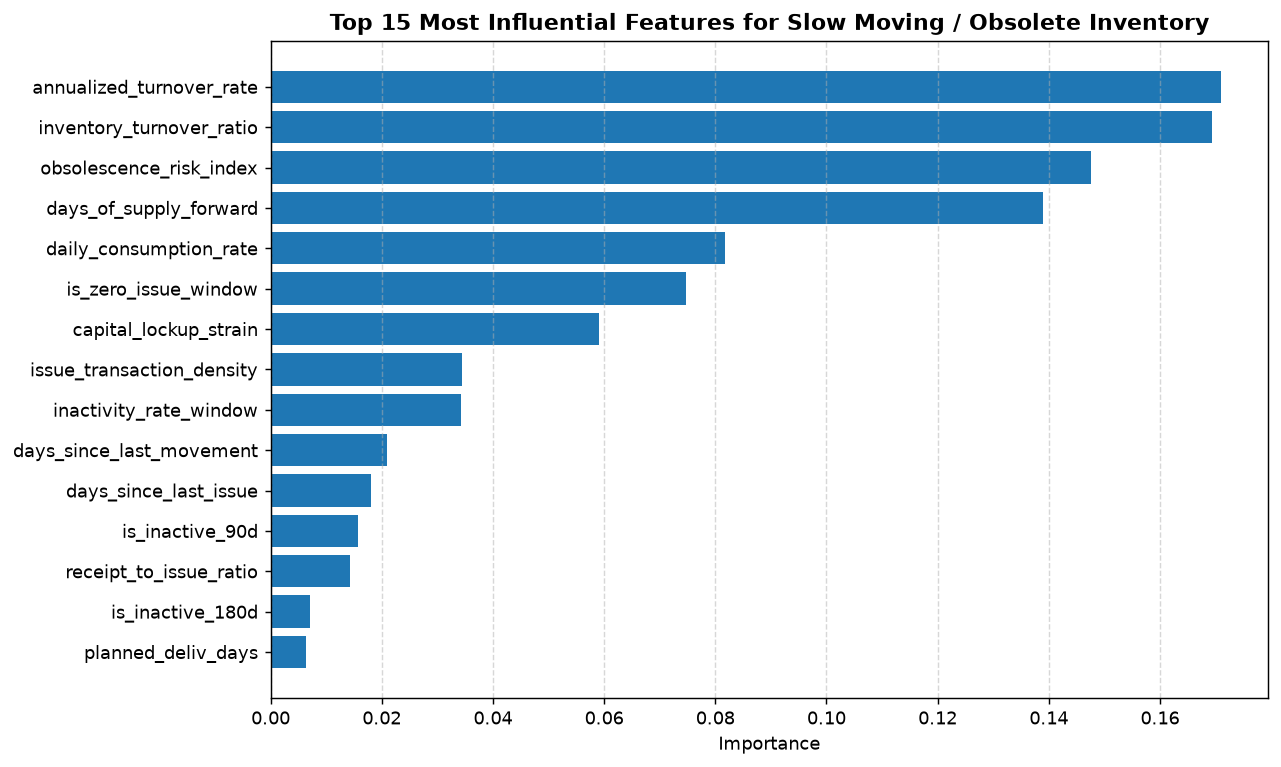

In [18]:
# 18. Surrogate Tree Feature Importance & Explainability
from src.evaluate import compute_feature_importance, plot_feature_importance

fi_sample = min(50000, len(X_train_scaled))
fi_df = compute_feature_importance(X_train_scaled[:fi_sample], y_train[:fi_sample], FEATURE_COLS)
fi_df.to_csv("reports/feature_importance.csv", index=False)
plot_feature_importance(fi_df, output_dir="reports/figures", top_n=15)

print("Top 10 Most Influential Obsolescence Features:")
display(fi_df.head(10))

plt.figure(figsize=(10, 6))
top15 = fi_df.head(15).sort_values(by='Importance', ascending=True)
plt.barh(top15['Feature'], top15['Importance'], color='#1f77b4')
plt.title("Top 15 Most Influential Features for Slow Moving / Obsolete Inventory", fontsize=12, fontweight='bold')
plt.xlabel("Importance")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [19]:
# 19. Prescriptive Action Recommendations
print("Prescriptive Action Distribution:")
display(scored_df['prescriptive_action'].value_counts().to_frame())


Prescriptive Action Distribution:
                                                     count
prescriptive_action                                       
CRITICAL ACTION: Dormant stock. Halt replenishm...  184124
NORMAL / ACTIVE: Fast-moving healthy inventory....   32073
HIGH PRIORITY: Slow-moving inventory. Freeze re...    9741
CRITICAL ACTION: High-value dead stock. Halt PO...    3069
MODERATE WATCH: Slower turnover. Review safety ...      91


In [20]:
# 20. Persisting Model Artifacts to models/
from src.inference import save_single_model_pipeline

save_single_model_pipeline(champion_segmenter, scaler, FEATURE_COLS, output_dir="models")
print("Saved champion model, scaler, and full pipeline bundle to models/")


[ARTIFACTS] Successfully persisted Champion Model to models\champion_slow_moving_model.joblib
[ARTIFACTS] Successfully persisted Scaler to models\slow_moving_scaler.joblib
[ARTIFACTS] Successfully persisted Full Bundle to models\slow_moving_model_bundle.joblib
Saved champion model, scaler, and full pipeline bundle to models/


In [21]:
# 21. Exporting Formatted Multi-Sheet Excel Deliverables
from src.inference import export_enriched_excel_report
import shutil

OUTPUT_EXCEL = "ML_6_Slow_Moving_Inventory_Prediction_Enriched_Output_Clean.xlsx"
export_enriched_excel_report(scored_df, output_path=OUTPUT_EXCEL, fi_df=fi_df, comp_df=comparison_df)

ALT_EXCEL = "ML_6_Slow_Moving_Inventory_Prediction_Enriched_Output.xlsx"
shutil.copyfile(OUTPUT_EXCEL, ALT_EXCEL)

print(f"Exported Enriched Multi-Sheet Excel Workbook: {OUTPUT_EXCEL}")
print(f"Copied Enriched Excel Workbook:              {ALT_EXCEL}")
print("ALL 21 STEPS COMPLETED SUCCESSFULLY!")



[REPORT] Generating styled executive Excel workbook: ML_6_Slow_Moving_Inventory_Prediction_Enriched_Output_Clean.xlsx (Records: 229,098)...
[REPORT] Successfully generated Excel workbook at: ML_6_Slow_Moving_Inventory_Prediction_Enriched_Output_Clean.xlsx
Exported Enriched Multi-Sheet Excel Workbook: ML_6_Slow_Moving_Inventory_Prediction_Enriched_Output_Clean.xlsx
Copied Enriched Excel Workbook:              ML_6_Slow_Moving_Inventory_Prediction_Enriched_Output.xlsx
ALL 21 STEPS COMPLETED SUCCESSFULLY!
